In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
df = pd.read_csv("../../data/processed/real_estate_data_updated.csv")
figures_dir = Path("../../results/data_processing/figures")
tables_dir = Path("../../results/data_processing/tables")

In [3]:
target = "Y house price of unit area"

numerical_features = [
    "X2 house age",
    "X3 distance to the nearest MRT station",
    "X4 number of convenience stores",
    "X5 latitude",
    "X6 longitude"
]

numerical_df = df[numerical_features + [target]]

features = numerical_features

x = numerical_df[features]
y = numerical_df[target]


In [5]:
# correlation matrix

corr_matrix = numerical_df.corr(method="pearson")

print("\n[1] complete correlation matrix")
print(corr_matrix.round(4))

corr_matrix.to_csv(tables_dir/"correlation_matrix.csv")


[1] complete correlation matrix
                                        X2 house age  \
X2 house age                                  1.0000   
X3 distance to the nearest MRT station        0.0256   
X4 number of convenience stores               0.0496   
X5 latitude                                   0.0544   
X6 longitude                                 -0.0485   
Y house price of unit area                   -0.2106   

                                        X3 distance to the nearest MRT station  \
X2 house age                                                            0.0256   
X3 distance to the nearest MRT station                                  1.0000   
X4 number of convenience stores                                        -0.6025   
X5 latitude                                                            -0.5911   
X6 longitude                                                           -0.8063   
Y house price of unit area                                             -0.6736   


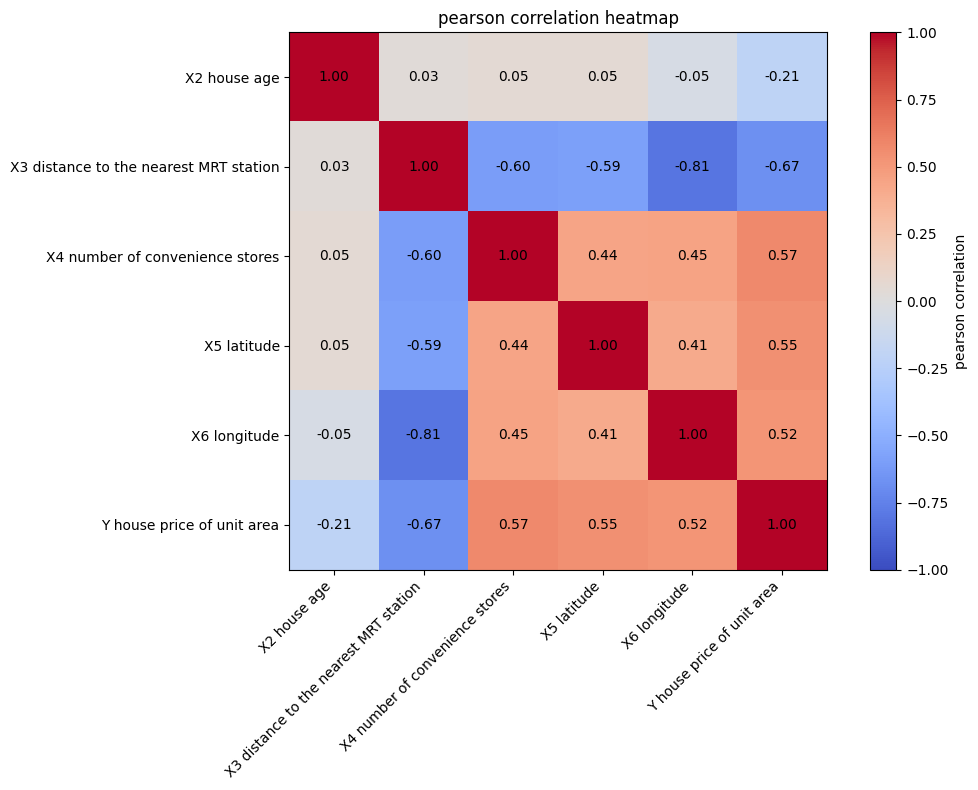

In [6]:
# correlation heatmap

plt.figure(figsize=(11, 8))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="pearson correlation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=45, 
    ha="right"
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("pearson correlation heatmap")

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        plt.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha = "center",
            va = "center"
        )

plt.tight_layout()

plt.savefig(
    figures_dir/"correlation_heatmap.png",
    dpi = 300,
    bbox_inches = "tight"
    )

plt.show()
plt.close()

In [7]:
# predictor vs target

print("\n[2] predictor vs target")

target_corr = corr_matrix[target].drop(target)

target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)

print(target_corr.round(4))



[2] predictor vs target
X3 distance to the nearest MRT station   -0.6736
X4 number of convenience stores           0.5710
X5 latitude                               0.5463
X6 longitude                              0.5233
X2 house age                             -0.2106
Name: Y house price of unit area, dtype: float64


In [8]:
# predictor vs predictor correlation

print("\n[3] predictor vs predictor correlation")

predictor_corr = x.corr(method="pearson")

upper_triangle = predictor_corr.where(
    np.triu(np.ones(predictor_corr.shape), k=1).astype(bool)
)

correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature_1", 
    "Feature_2",
    "Correlation"
]

correlation_pairs["Absolute_Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    by="Absolute_Correlation",
    ascending=False
)

print(correlation_pairs.to_string(index=False))

correlation_pairs.to_csv(
    tables_dir/"predictor_correlation_pairs.csv",
    index=False
)


[3] predictor vs predictor correlation
                             Feature_1                              Feature_2  Correlation  Absolute_Correlation
X3 distance to the nearest MRT station                           X6 longitude    -0.806317              0.806317
X3 distance to the nearest MRT station        X4 number of convenience stores    -0.602519              0.602519
X3 distance to the nearest MRT station                            X5 latitude    -0.591067              0.591067
       X4 number of convenience stores                           X6 longitude     0.449099              0.449099
       X4 number of convenience stores                            X5 latitude     0.444143              0.444143
                           X5 latitude                           X6 longitude     0.412924              0.412924
                          X2 house age                            X5 latitude     0.054420              0.054420
                          X2 house age        X4 number 

In [9]:
# identify high correlation pairs

print("\n[4] high correlation pairs")

threshold = 0.7

high_corr = correlation_pairs[
    correlation_pairs["Absolute_Correlation"] >= threshold
]

if high_corr.empty:
    print("No predictor pairs crossed the selected threshold")
else:
    print(high_corr.to_string(index=False))


[4] high correlation pairs
                             Feature_1    Feature_2  Correlation  Absolute_Correlation
X3 distance to the nearest MRT station X6 longitude    -0.806317              0.806317
